Exploratory Data Analysis of Telco Customer Churn dataset.

Each row represents a customer, each column contains customer’s attributes described on the column Metadata.

The data set includes information about:

- Customers who left within the last month – the column is called Churn
- Services that each customer has signed up for – phone, multiple lines, internet, online security, online backup, device protection, tech support, and streaming TV and movies
- Customer account information – how long they’ve been a customer, contract, payment method, paperless billing, monthly charges, and total charges
- Demographic info about customers – gender, age range, and if they have partners and dependents

This dataset is located in kaggle : https://www.kaggle.com/datasets/blastchar/telco-customer-churn?resource=download

Import the main packages of python

In [2]:
# === Imports ===
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# General Configuration
pd.set_option('display.max_columns', None)
plt.style.use("ggplot")

Load dataset

In [3]:
# Load dataset
df = pd.read_csv("../data/churn.csv")  # ajusta la ruta según tu carpeta

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


General Information

In [4]:
df["TotalCharges"].dtype


dtype('O')

In [5]:
# Raw information about the dataset

df.info

<bound method DataFrame.info of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  \
0              No  No phone service             DSL      

Informateve stadistics


In [6]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,8945-MUQUF,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Nule values

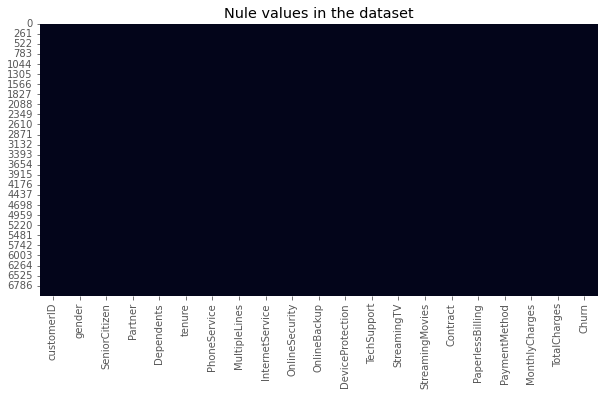

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Nule values in the dataset")
plt.show()

df.isnull().sum()

Correction of the column Totalcharges

In [8]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
# Check NaN values
df["TotalCharges"].isna().sum()


11

In [9]:
# Eliminate NaN values
df = df.dropna(subset=["TotalCharges"])

Objetive variable distribution (Churn)

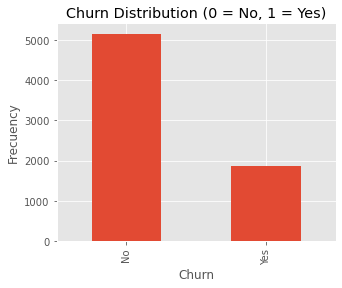

No     0.734215
Yes    0.265785
Name: Churn, dtype: float64

In [10]:
plt.figure(figsize=(5,4))
df['Churn'].value_counts().plot(kind='bar')
plt.title("Churn Distribution (0 = No, 1 = Yes)")
plt.xlabel("Churn")
plt.ylabel("Frecuency")
plt.show()

df['Churn'].value_counts(normalize=True)

Numeric valriables distributions

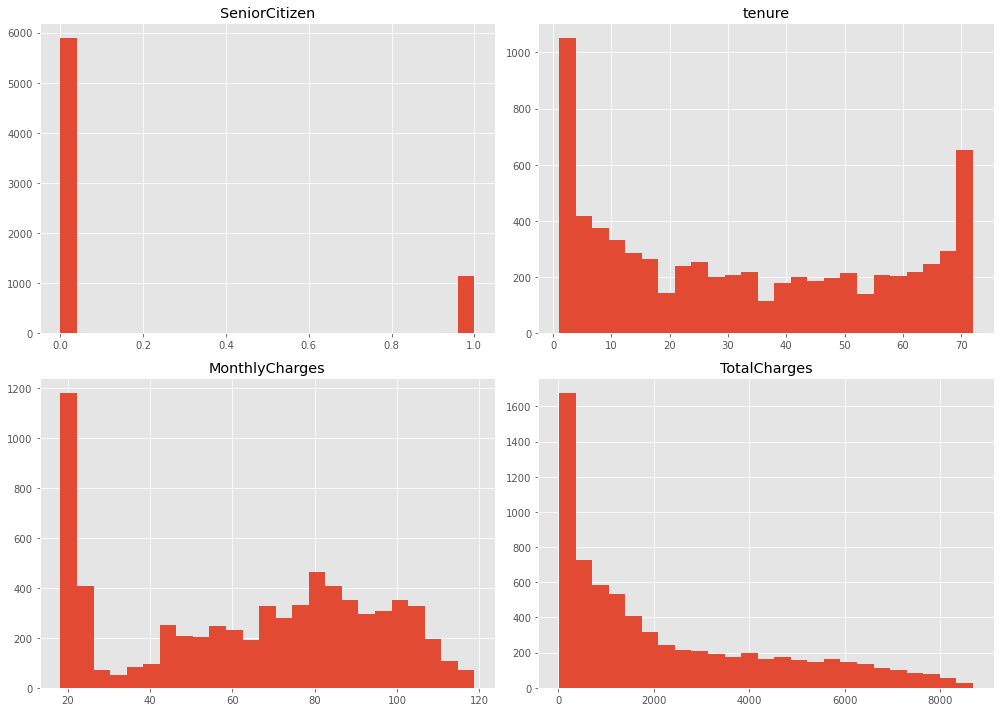

In [11]:
df.hist(figsize=(14,10), bins=25)
plt.tight_layout()
plt.show()

Outlinet Boxplot

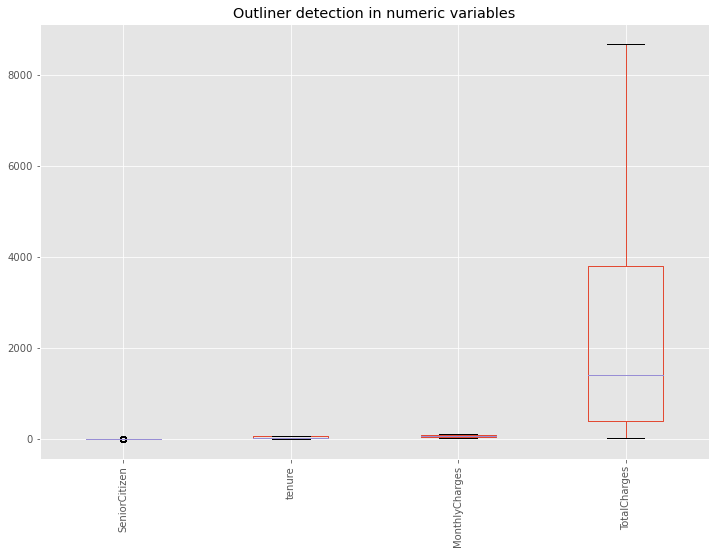

In [12]:
numeric_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(12,8))
df[numeric_cols].boxplot()
plt.title("Outliner detection in numeric variables")
plt.xticks(rotation=90)
plt.show()

Variable Correlation

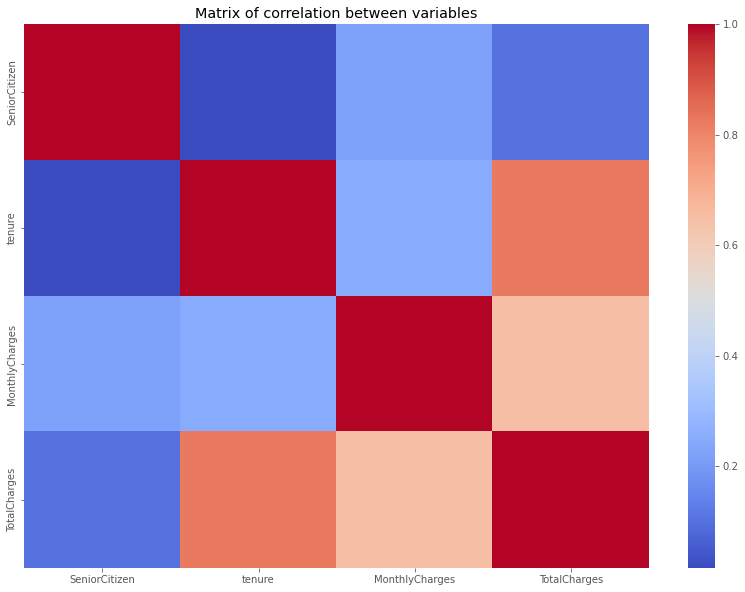

In [13]:
plt.figure(figsize=(14,10))
sns.heatmap(df.corr(), annot=False, cmap="coolwarm")
plt.title("Matrix of correlation between variables")
plt.show()

Relation between relevant variables and Churn

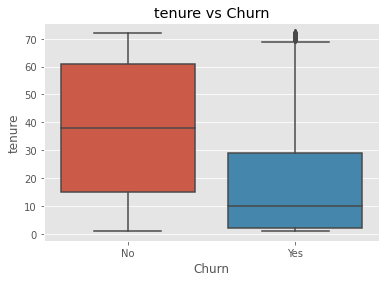

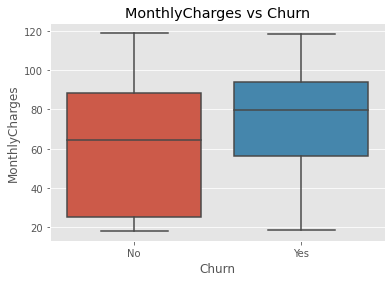

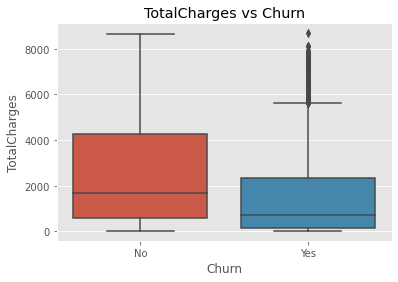

In [14]:
features = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in features:
    plt.figure(figsize=(6,4))
    sns.boxplot(data=df, x='Churn', y=col)
    plt.title(f'{col} vs Churn')
    plt.show()

Analysis of categorical variables

this categories will be eliminate by be too big to do analysis: ['customerID']
Analyzing the nex categories ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


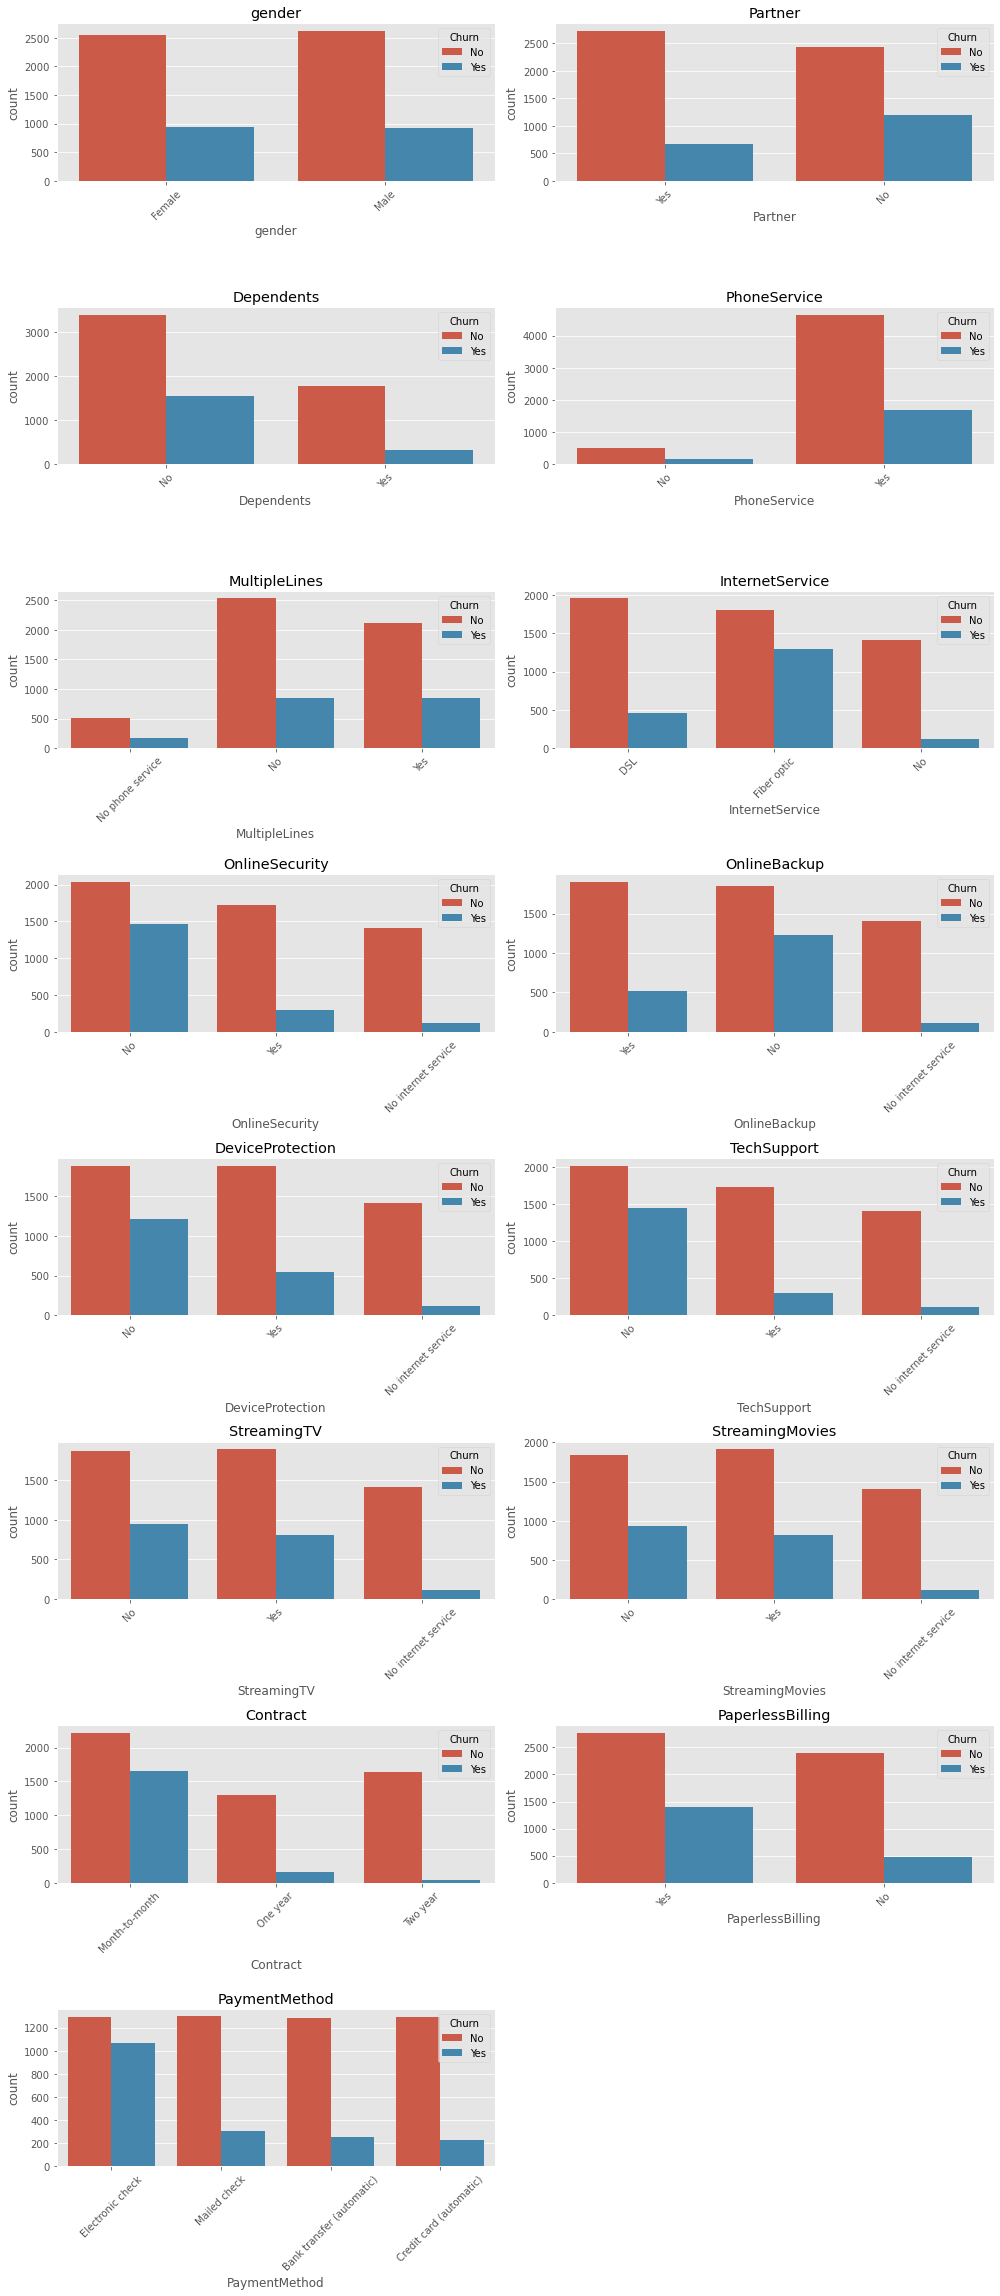

In [ ]:
# Selection of categorical columns
cat_cols = [c for c in df.select_dtypes(include=['object', 'category']).columns if c != 'Churn']

# filtering columns of too much categories (more than 12)
dropping_cols = [c for c in cat_cols if df[c].nunique() > 12]
print("this categories will be eliminate by be too big to do analysis:", dropping_cols)
cat_cols = [c for c in cat_cols if df[c].nunique() <= 12]



print("Analyzing the nex categories", cat_cols)

n = len(cat_cols)
rows = (n + 1) // 2
plt.figure(figsize=(14, 4 * rows))

for i, col in enumerate(cat_cols, 1):
    plt.subplot(rows, 2, i)
    sns.countplot(data=df, x=col, hue="Churn")
    plt.xticks(rotation=45)
    plt.title(col)

plt.tight_layout()
plt.show()

Change Churn values from "yes" / "no" to [1,0]

In [ ]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})


Save clean database

In [22]:
df.to_csv("../data/churn_cleaned.csv", index=False)
import os

print(os.listdir("../data"))


['churn.csv', 'churn_cleaned.csv']
